In [3]:
import pandas as pd
import numpy as np
from collections import Counter
import collections
from pathlib import Path
import os
import random
import matplotlib.pyplot as plt
#for text pre-processing
import re, string
import nltk

nltk.download('stopwords')
nltk.download('omw-1.4')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')
#for model-building
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, roc_auc_score
# bag of words
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
#for word embedding
import gensim
from gensim.models import Word2Vec

[nltk_data] Downloading package stopwords to /home/javi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/javi/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /home/javi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/javi/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /home/javi/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [5]:


##INPUT FILES HERE ##

#DEBBIE dataset.



#training set
training_set = [os.path.join("classifier-dataset/dataset/trainning_set", f) for f in os.listdir("classifier-dataset/dataset/trainning_set")]

#test_set 
test_set = [os.path.join("classifier-dataset/dataset/test_set", f) for f in os.listdir("classifier-dataset/dataset/test_set")]

#clarence dataset

#training set
#training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts")]

#test_set 
#test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts")]

training_set = random.sample(training_set, len(training_set))
test_set = random.sample(test_set, len(test_set))

print("Total: " + str(len(training_set) + len(test_set)))
print("Training Set: " + str(len(training_set)))
print("Test Set: " + str(len(test_set)))
#print (training_set)
#print(test_set)

Total: 4165
Training Set: 2915
Test Set: 1250


In [6]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass training and test set
training_set_labels, file_list, combined_training = make_labels(training_set)
test_set_labels, test_file_list, combined_testing  = make_labels(test_set)


df_train = pd.DataFrame(data={'files': training_set, 'target':training_set_labels})
df_test = pd.DataFrame(data={'files': test_set, 'target':test_set_labels})


{'non-clinical': 'classifier-dataset/dataset/trainning_set/30154869_non-clinical.txt', 'non-relevant': 'classifier-dataset/dataset/trainning_set/20596394_background.txt', 'clinical': 'classifier-dataset/dataset/trainning_set/22426939_clinical.txt'}
{'non-clinical': 'classifier-dataset/dataset/test_set/23267692_non-clinical.txt', 'non-relevant': 'classifier-dataset/dataset/test_set/20571690_background.txt', 'clinical': 'classifier-dataset/dataset/test_set/24434382_clinical.txt'}


Counter({'non-relevant': 1232, 'non-clinical': 844, 'clinical': 839})
[839, 844, 1232]


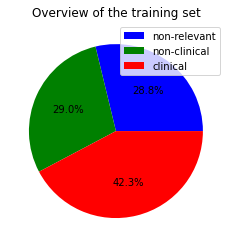

In [7]:
# to represent the distribution of the training set in a circular diagram

labels = ['non-relevant','non-clinical','clinical']

sizes = Counter(training_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the training set')
plt.show()

Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
[248, 361, 641]


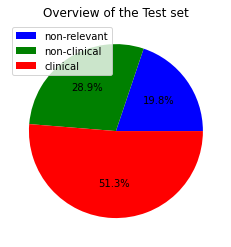

In [8]:
# to represent the distribution of the test:


labels = ['non-relevant','non-clinical','clinical']

sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [9]:
#convert to lowercase, strip and remove punctuations
def preprocess(text):
    text = text.lower() 
    text=text.strip()  
    text=re.compile('<.*?>').sub('', text) 
    text = re.compile('[%s]' % re.escape(string.punctuation)).sub(' ', text)  
    text = re.sub('\s+', ' ', text)  
    text = re.sub(r'\[[0-9]*\]',' ',text) 
    text=re.sub(r'[^\w\s]', '', str(text).lower().strip())
    text = re.sub(r'\d',' ',text) 
    text = re.sub(r'\s+',' ',text) 
    return text
 
# STOPWORD REMOVAL
def stopword(string):
    a= [i for i in string.split() if i not in stopwords.words('english')]
    return ' '.join(a)#LEMMATIZATION
# Initialize the lemmatizer
wl = WordNetLemmatizer()
 
# This is a helper function to map NTLK position tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN# Tokenize the sentence

def lemmatizer(string):
    word_pos_tags = nltk.pos_tag(word_tokenize(string)) # Get position tags
    #a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) + '_' + get_wordnet_pos(tag[1]) for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    #a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) + '_' + tag[1] for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    return " ".join(a)

def finalpreprocess(string):
    return lemmatizer(stopword(preprocess(string)))
    #return lemmatizer(preprocess(string))

In [10]:
#load text of files 
X_train = [Path(file).read_text() for file in training_set]
X_test = [Path(file).read_text() for file in test_set]



In [11]:
X_train_preprocessed = [finalpreprocess(string) for string in X_train]
X_test_preprocessed = [finalpreprocess(string) for string in X_test]

In [12]:
df_train['text_preprocessed']=X_train_preprocessed
df_test[ 'text_preprocessed']=X_test_preprocessed 
#df_test['text_preprocessed_pos'] = [Path(file).read_text() for file in X_train_preprocessed]

df_train.head()

,files,target,text_preprocessed
0,classifier-dataset/dataset/trainning_set/24009...,non-clinical,promotion_n peripheral_a nerve_n regeneration_...
1,classifier-dataset/dataset/trainning_set/21299...,non-relevant,mechanism_n resistance_n bcr_n abl_n kinase_n ...
2,classifier-dataset/dataset/trainning_set/26748...,non-relevant,spleen_a enlargement_n risk_n factor_n thrombo...
3,classifier-dataset/dataset/trainning_set/25376...,non-clinical,enhance_v cell_n migration_n shape_n memory_n ...
4,classifier-dataset/dataset/trainning_set/24286...,clinical,radiographic_a stent_n integrate_v treatment_n...


In [14]:
#Vectorization using Bag-of-Words (with Tf-Idf )
#Tf-Idf
tfidf_vectorizer = TfidfVectorizer(use_idf=True)
X_train_vectors_tfidf = tfidf_vectorizer.fit_transform(X_train_preprocessed) 
X_test_vectors_tfidf = tfidf_vectorizer.transform(X_test_preprocessed)


In [18]:
#option I: SGD muticlass Logistic Regression
sgd_clf = SGDClassifier(loss= 'log', penalty= 'l2').fit(X_train_vectors_tfidf, training_set_labels)
#Predict y value for test dataset
y_predict = sgd_clf.predict(X_test_vectors_tfidf)
y_prob = sgd_clf.predict_proba(X_test_vectors_tfidf)[:,1]
print("Bag-of-Words (with Tf-Idf ) with SGDClassifier Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))
 

Bag-of-Words (with Tf-Idf ) with SGDClassifier Logistic Regression
              precision    recall  f1-score   support

    clinical       0.70      0.89      0.79       248
non-clinical       0.96      0.94      0.95       361
non-relevant       0.93      0.85      0.89       641

    accuracy                           0.88      1250
   macro avg       0.87      0.89      0.88      1250
weighted avg       0.90      0.88      0.89      1250

Confusion Matrix: [[221   6  21]
 [  2 341  18]
 [ 92   7 542]]


In [74]:
#option 2: SGD muticlass 
sgd_clf_2 = SGDClassifier().fit(X_train_vectors_tfidf, training_set_labels)
#Predict y value for test dataset
y_predict = sgd_clf_2.predict(X_test_vectors_tfidf)
#y_prob = sgd_clf_2.predict_proba(X_test_vectors_tfidf)[:,1]
print("Bag-of-Words (with Tf-Idf ) with SGDClassifier SVM")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Bag-of-Words (with Tf-Idf ) with SGDClassifier SVM
              precision    recall  f1-score   support

    clinical       0.65      0.87      0.74       248
non-clinical       0.96      0.96      0.96       361
non-relevant       0.93      0.81      0.87       641

    accuracy                           0.86      1250
   macro avg       0.85      0.88      0.86      1250
weighted avg       0.88      0.86      0.87      1250

Confusion Matrix: [[215   5  28]
 [  4 345  12]
 [111  10 520]]


In [75]:
#option 3: LogisticRegression 
lr_tfidf=LogisticRegression(solver = 'liblinear', C=10, penalty = 'l2')
lr_tfidf.fit(X_train_vectors_tfidf, training_set_labels)  
#Predict y value for test dataset
y_predict = lr_tfidf.predict(X_test_vectors_tfidf)
y_prob = lr_tfidf.predict_proba(X_test_vectors_tfidf)[:,1]
print("Bag-of-Words (with Tf-Idf ) with Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Bag-of-Words (with Tf-Idf ) with Logistic Regression
              precision    recall  f1-score   support

    clinical       0.69      0.87      0.77       248
non-clinical       0.96      0.94      0.95       361
non-relevant       0.92      0.84      0.88       641

    accuracy                           0.88      1250
   macro avg       0.86      0.88      0.87      1250
weighted avg       0.89      0.88      0.88      1250

Confusion Matrix: [[216   6  26]
 [  2 340  19]
 [ 93   9 539]]


In [43]:
#Option 4 Naive Bayes
nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_vectors_tfidf, training_set_labels) 
#Predict y value for test dataset
y_predict = nb_tfidf.predict(X_test_vectors_tfidf)
y_prob = nb_tfidf.predict_proba(X_test_vectors_tfidf)[:,1]
print("Bag-of-Words (with Tf-Idf ) with Naive Bayes")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Bag-of-Words (with Tf-Idf ) with Naive Bayes
              precision    recall  f1-score   support

    clinical       0.67      0.89      0.77       248
non-clinical       0.91      0.98      0.94       361
non-relevant       0.96      0.79      0.87       641

    accuracy                           0.87      1250
   macro avg       0.85      0.89      0.86      1250
weighted avg       0.89      0.87      0.87      1250

Confusion Matrix: [[221  10  17]
 [  2 355   4]
 [106  26 509]]


In [44]:
#Word2Vec Vectorization
# Word2Vec runs on tokenized sentences
# this is for later
X_train_tok= [nltk.word_tokenize(i) for i in X_train_preprocessed]  
X_test_tok= [nltk.word_tokenize(i) for i in X_test_preprocessed]
df_train['tok']=X_train_tok
print(df_train)

                                                  files        target  \
0     classifier-dataset/dataset/trainning_set/21876...  non-relevant   
1     classifier-dataset/dataset/trainning_set/29367...  non-relevant   
2     classifier-dataset/dataset/trainning_set/29046...  non-clinical   
3     classifier-dataset/dataset/trainning_set/24452...      clinical   
4     classifier-dataset/dataset/trainning_set/19335...  non-clinical   
5     classifier-dataset/dataset/trainning_set/24029...  non-clinical   
6     classifier-dataset/dataset/trainning_set/29089...  non-clinical   
7     classifier-dataset/dataset/trainning_set/23657...      clinical   
8     classifier-dataset/dataset/trainning_set/26199...  non-relevant   
9     classifier-dataset/dataset/trainning_set/21482...  non-relevant   
10    classifier-dataset/dataset/trainning_set/28224...  non-relevant   
11    classifier-dataset/dataset/trainning_set/22889...      clinical   
12    classifier-dataset/dataset/trainning_set/2030

In [45]:
#building Word2Vec model
class MeanEmbeddingVectorizer(object):
    def __init__(self, word2vec):
        self.word2vec = word2vec
        # if a text is empty we should return a vector of zeros
        # with the same dimensionality as all the other vectors
        self.dim = len(next(iter(word2vec.values())))
    def fit(self, X, y):
        return self
    def transform(self, X):
        return np.array([
            np.mean([self.word2vec[w] for w in words if w in self.word2vec]
                    or [np.zeros(self.dim)], axis=0)
            for words in X
        ])

df_train['clean_text_tok']=[nltk.word_tokenize(i) for i in X_train_preprocessed]
model = Word2Vec(df_train['clean_text_tok'],min_count=1)   

w2v = dict(zip(model.wv.index_to_key, model.wv.vectors)) 
modelw = MeanEmbeddingVectorizer(w2v)
# converting text to numerical data using Word2Vec
X_train_vectors_w2v = modelw.transform(X_train_tok)
X_val_vectors_w2v = modelw.transform(X_test_tok)

print (X_train_vectors_w2v)

[[-0.00268215  0.45392245  0.12629259 ... -0.35336003  0.03161876
   0.16731018]
 [-0.14336684  0.5522949   0.25437906 ... -0.45918712  0.15729989
  -0.10264356]
 [ 0.12191534  0.5215652   0.05352708 ... -0.38934022  0.02244705
   0.20452961]
 ...
 [ 0.34439626  0.68366563 -0.04711907 ... -0.38507524 -0.0889385
   0.28330633]
 [-0.12783515  0.21572259  0.1091203  ... -0.57461643  0.24162318
   0.00445882]
 [-0.45602566  0.24725392  0.3545259  ... -0.79951096  0.41100436
  -0.23739192]]


In [46]:
#option I: SGD muticlass Logistic Regression
sgd_clf = SGDClassifier(loss= 'log', penalty= 'l2').fit(X_train_vectors_w2v, training_set_labels)
#Predict y value for test dataset
y_predict = sgd_clf.predict(X_val_vectors_w2v)
y_prob = sgd_clf.predict_proba(X_val_vectors_w2v)[:,1]
print("Word2Vec with SGDClassifier Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Word2Vec with SGDClassifier Logistic Regression
              precision    recall  f1-score   support

    clinical       0.63      0.92      0.75       248
non-clinical       0.96      0.94      0.95       361
non-relevant       0.95      0.79      0.86       641

    accuracy                           0.86      1250
   macro avg       0.85      0.88      0.85      1250
weighted avg       0.89      0.86      0.86      1250

Confusion Matrix: [[228   4  16]
 [  7 341  13]
 [125  11 505]]


In [47]:
#option 2: SGD muticlass 
sgd_clf_2 = SGDClassifier().fit(X_train_vectors_w2v, training_set_labels)
#Predict y value for test dataset
y_predict = sgd_clf_2.predict(X_val_vectors_w2v)
#y_prob = sgd_clf_2.predict_proba(X_test_vectors_tfidf)[:,1]
print("Word2Vec with SGDClassifier SVM")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Word2Vec with SGDClassifier SVM
              precision    recall  f1-score   support

    clinical       0.58      0.94      0.72       248
non-clinical       0.86      0.98      0.92       361
non-relevant       0.97      0.67      0.79       641

    accuracy                           0.81      1250
   macro avg       0.81      0.86      0.81      1250
weighted avg       0.86      0.81      0.81      1250

Confusion Matrix: [[233   8   7]
 [  4 353   4]
 [165  49 427]]


In [48]:
#option 3: LogisticRegression 
lr_tfidf=LogisticRegression(solver = 'liblinear', C=10, penalty = 'l2')
lr_tfidf.fit(X_train_vectors_w2v, training_set_labels)  
#Predict y value for test dataset
y_predict = lr_tfidf.predict(X_val_vectors_w2v)
y_prob = lr_tfidf.predict_proba(X_val_vectors_w2v)[:,1]
print("Word2Vec with Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

Word2Vec with Logistic Regression
              precision    recall  f1-score   support

    clinical       0.65      0.91      0.76       248
non-clinical       0.93      0.96      0.95       361
non-relevant       0.95      0.79      0.86       641

    accuracy                           0.86      1250
   macro avg       0.85      0.89      0.86      1250
weighted avg       0.89      0.86      0.87      1250

Confusion Matrix: [[226   6  16]
 [  5 346  10]
 [115  19 507]]


In [54]:
#Option 4 Naive Bayes, not work with negative values
nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_vectors_w2v, training_set_labels) 
#Predict y value for test dataset
y_predict = nb_tfidf.predict(X_val_vectors_w2v)

print("Word2Vec with Naive Bayes")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))

ValueError: Negative values in data passed to MultinomialNB (input X)

In [ ]:
#here is a test of cross validation using the 
X, y = df_train['data'], df_train['label']
metrics = []

skf = StratifiedKFold(n_splits=5)
for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    vect = CountVectorizer(ngram_range=(1,2), max_features=1000 , stop_words="English")
    X_train_dtm = vect.fit_transform(X_train)
    X_test_dtm = vect.transform(X_test)
    nb = MultinomialNB()
    nb.fit(X_train_dtm, y_train)
    y_pred_class = nb.predict(X_test_dtm)

    metrics.append(accuracy_score(y_test, y_pred_class))

metrics = numpy.array(metrics)
print('Mean accuracy: ', numpy.mean(metrics, axis=0))
print('Std for accuracy: ', numpy.std(metrics, axis=0))



#option I: SGD muticlass Logistic Regression
sgd_clf = SGDClassifier(loss= 'log', penalty= 'l2').fit(X_train_vectors_tfidf, training_set_labels)
#Predict y value for test dataset
y_predict = sgd_clf.predict(X_test_vectors_tfidf)
y_prob = sgd_clf.predict_proba(X_test_vectors_tfidf)[:,1]
print("Bag-of-Words (with Tf-Idf ) with SGDClassifier Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))
 
